# Self-Healing Work Cell — walkthrough notebook

Run the cells top to bottom (Shift+Enter). Each section is one step of the project, using the
real code and the real results.

- **Kernel:** "Python (selfheal .venv)" — the project's own Python. On another computer:
  `python -m venv .venv`, `pip install -r requirements.txt jupyter`.
- **Cost:** everything is free except the last cell, which calls a model on Nebius (< 1 cent)
  and is switched off unless you set `RUN_LIVE = True`.
- **Needs** the rendered scenes and results in `runs/` (not on GitHub). Without them, the
  cells that need them say so and skip.
- Full explanations: `journal/GUIDE.md`.

In [1]:
import json, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
for p in (ROOT, ROOT / "isaac", ROOT / "scripts", ROOT / "eval"):
    sys.path.insert(0, str(p))

import matplotlib.pyplot as plt
from PIL import Image

SCENES = ROOT / "runs" / "scenes" / "feval_v1"   # the 120 held-out nut/bolt scenes
BENCH = ROOT / "runs" / "bench"
HAVE_RUNS = SCENES.exists()
print("project:", ROOT)
print("rendered scenes available:", HAVE_RUNS)

project: /home/ubuntu/nvidia_nebius_challenge_ws
rendered scenes available: True


## Step 1 — a seed becomes a scene, with its correct answer

`isaac/faults.py` turns one number into a complete scene description. No simulator needed for
this part: Isaac Sim only *draws* what this decides. Seed 5009 is in the held-out set.

In [2]:
import faults

SEED = 5009
spec = faults.make_scene(SEED, "fastener")
print("fault class :", spec.fault, "(seed % 6 =", SEED % 6, ")")
print("checkpoint  :", spec.checkpoint)
print("details     :", spec.truth)
print("right answer:", spec.expected)

fault class : F5 (seed % 6 = 5 )
checkpoint  : CP_PRE_GRASP
details     : {'defect': 'chip', 'chip_mm': 4.04, 'chip_corner': 4}
right answer: Expected(checkpoint='CP_PRE_GRASP', step_ok=False, failure_type='defective_part', location_hint='carrier')


In [3]:
# Every 6 seeds in a row cover the 6 fault classes once.
for s in range(5000, 5012):
    sc = faults.make_scene(s, "fastener")
    print(s, sc.fault, f"{sc.checkpoint:<18}", f"{sc.expected.failure_type:<27}", sc.truth)

5000 F2 CP_POST_TRANSPORT  part_dropped_recoverable    {'landing_region': 'table'}
5001 F3 CP_POST_PLACE      misaligned_seat             {'offset_mm': 11.09, 'tilt_deg': 6.19}
5002 F4 CP_PRE_GRASP       wrong_part                  {'wrong_shape': 'nut_m20'}
5003 F5 CP_PRE_GRASP       defective_part              {'defect': 'rust', 'rust_coverage': 0.344}
5004 F0 CP_POST_TRANSPORT  none                        {}
5005 F1 CP_PRE_GRASP       part_displaced              {'offset_mm': 12.07, 'yaw_deg': -20.54}
5006 F2 CP_POST_TRANSPORT  part_dropped_recoverable    {'landing_region': 'table'}
5007 F3 CP_POST_PLACE      misaligned_seat             {'offset_mm': 11.7, 'tilt_deg': 8.64}
5008 F4 CP_PRE_GRASP       wrong_part                  {'wrong_shape': 'bolt_m16'}
5009 F5 CP_PRE_GRASP       defective_part              {'defect': 'chip', 'chip_mm': 4.04, 'chip_corner': 4}
5010 F0 CP_POST_PLACE      none                        {}
5011 F1 CP_POST_LIFT       empty_grasp                 {'offset_

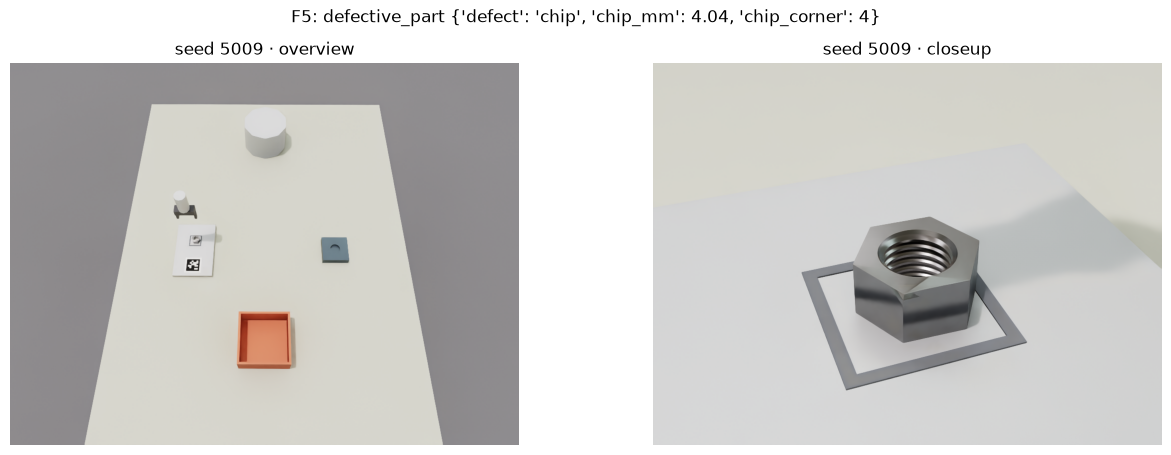

In [4]:
# The two photos Isaac Sim rendered for this seed: what every model is shown.
def show_scene(seed, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
    for ax, view in zip(axes, ("overview", "closeup")):
        ax.imshow(Image.open(SCENES / "images" / f"{seed}_{view}.png"))
        ax.set_title(f"seed {seed} · {view}"); ax.axis("off")
    if title:
        fig.suptitle(title)
    plt.tight_layout(); plt.show()

if HAVE_RUNS:
    show_scene(SEED, f"{spec.fault}: {spec.expected.failure_type} {spec.truth}")
else:
    print("no rendered scenes here: run `make demo` on the Isaac Sim machine")

## Step 2 — the verifier: what each model said about this scene

Every model got the same prompt and the same two photos. Their raw replies were parsed into
the strict `Verdict` JSON (`selfheal/verdict.py`) and compared with the right answer.

In [5]:
RUNS = {
    "Gemma 3 27B (Google, zero-shot)":       "feval_v1__fastener-v1",
    "Cosmos-Reason1-7B (NVIDIA, zero-shot)": "feval_v1__cosmos_base",
    "Cosmos-Reason1-7B + our LoRA":          "feval_v1__cosmos_tuned",
    "Nemotron-Nano-12B-v2-VL (NVIDIA, zero-shot)": "feval_v1__nemotron_vl",
}

def load_rows(run):
    f = BENCH / run / "results.jsonl"
    return {json.loads(l)["seed"]: json.loads(l) for l in f.read_text().splitlines()} if f.exists() else None

print("right answer:", spec.expected.failure_type, "\n")
for name, run in RUNS.items():
    rows = load_rows(run)
    if rows is None:
        print(f"{name:<45} (not run yet)"); continue
    p = rows[SEED]["pred"] or {}
    mark = "✓" if p.get("failure_type") == spec.expected.failure_type else "✗"
    print(f"{mark} {name:<43} {p.get('failure_type')!s:<16} {p.get('evidence', '')}")

right answer: defective_part 

✗ Gemma 3 27B (Google, zero-shot)             none             The part appears to be a hex nut of the correct size and shape, with no visible damage, and is positioned inside the printed square.
✗ Cosmos-Reason1-7B (NVIDIA, zero-shot)       part_displaced   The M16 hex nut is displaced from the printed square outline on the carrier tile, indicating it has moved out of position before the grasp attempt.
✓ Cosmos-Reason1-7B + our LoRA                defective_part   One corner of the nut is cut off, showing a bright slanted facet.
✗ Nemotron-Nano-12B-v2-VL (NVIDIA, zero-shot) wrong_part       The part is a bolt, not an M16 hex nut.


In [6]:
# How a messy model reply becomes a strict verdict. Reasoning models wrap the JSON in a
# <think> block and a code fence; strip_to_json removes both, Verdict checks every field.
from selfheal.verdict import Verdict, strip_to_json

raw = '<think>one corner looks cut</think>```json\n{"checkpoint":"CP_PRE_GRASP","step_ok":false,"failure_type":"defective_part","evidence":"corner cut off","location_hint":"carrier","confidence":0.8}\n```'
print(Verdict.model_validate_json(strip_to_json(raw)))

try:
    Verdict.model_validate_json('{"checkpoint":"CP_PRE_GRASP","step_ok":false,"failure_type":"broken","evidence":"x","location_hint":"carrier","confidence":0.8}')
except Exception as e:
    print("\nrejected:", str(e).splitlines()[0], "-> 'broken' is not an allowed failure_type")

checkpoint='CP_PRE_GRASP' step_ok=False failure_type='defective_part' evidence='corner cut off' location_hint='carrier' confidence=0.8

rejected: 1 validation error for Verdict -> 'broken' is not an allowed failure_type


## Step 3 — deciding what to do: sensor fusion, planner, guardrails

- **Fusion** (`selfheal/fusion.py`): the gripper's finger sensor overrules the camera on
  "is something in the hand".
- **Planner**: Nemotron picks one of 5 tools (a live call, so not run here).
- **Guardrail** (`selfheal/planner.py`): code that overrules an unsafe planner choice.
- **Policies** (`selfheal/policies.py`): A no checks · B today's factory · C ours with
  Nemotron · D ours with a lookup table.

In [7]:
from selfheal.fusion import fuse, gripper_signal

# The camera says "holding the part", but the fingers closed all the way: nothing is held.
camera_says = {"checkpoint": "CP_POST_LIFT", "step_ok": True, "failure_type": "none",
               "evidence": "part between the fingers", "location_hint": "gripper", "confidence": 0.9}
fused, rule = fuse(camera_says, gripper_signal(closed=True, holding=False), "CP_POST_LIFT")
print("rule fired:", rule)
print("fused     :", fused["failure_type"], "/", fused["evidence"])

rule fired: sensor_empty_forces_empty_grasp
fused     : empty_grasp / [sensor: fingers fully closed] part between the fingers


In [8]:
from selfheal.planner import guardrail, WHITELIST

print("the 5 tools:", sorted(WHITELIST), "\n")
for tool, failure in [("continue_cycle", "defective_part"), ("reseat_part", "unclear"),
                      ("move_arm_to_xyz", "part_displaced"), ("reject_to_bin", "wrong_part")]:
    final, note = guardrail(tool, failure)
    print(f"planner chose {tool:<16} for {failure:<15} -> {final:<15} {note or '(allowed)'}")

the 5 tools: ['continue_cycle', 'reject_to_bin', 'relocalize_and_regrasp', 'reseat_part', 'stop_and_alert'] 

planner chose continue_cycle   for defective_part  -> reject_to_bin   defective_part must go to the bin, model chose continue_cycle
planner chose reseat_part      for unclear         -> stop_and_alert  unclear verdict: never guess, model chose reseat_part
planner chose move_arm_to_xyz  for part_displaced  -> stop_and_alert  tool 'move_arm_to_xyz' not in whitelist
planner chose reject_to_bin    for wrong_part      -> reject_to_bin   (allowed)


In [9]:
from selfheal.policies import policy_b, policy_d, outcome

# The chipped nut from step 1, judged by today's factory (B) and by our verifier + table (D).
b = policy_b(checkpoint="CP_PRE_GRASP", signal="open")
d = policy_d(fused={"step_ok": False, "failure_type": "defective_part", "location_hint": "carrier"})
print("B, gripper sensor only:", b, "->", outcome(b, "defective_part", "carrier"))
print("D, camera verifier    :", d, "->", outcome(d, "defective_part", "carrier"))

B, gripper sensor only: ('continue_cycle', None) -> quality_escape
D, camera verifier    : ('reject_to_bin', None) -> correct


## Step 4 — the results on all 120 held-out scenes

verifier                                       correct  false alarms   missed   p50 ms
Gemma 3 27B (Google, zero-shot)                  48.3%          0.0%    52.0%     2288
Cosmos-Reason1-7B (NVIDIA, zero-shot)            21.7%         50.0%    30.0%     1891
Cosmos-Reason1-7B + our LoRA                     94.2%         25.0%     0.0%     2592
Nemotron-Nano-12B-v2-VL (NVIDIA, zero-shot)      38.3%         55.0%    38.0%    27430


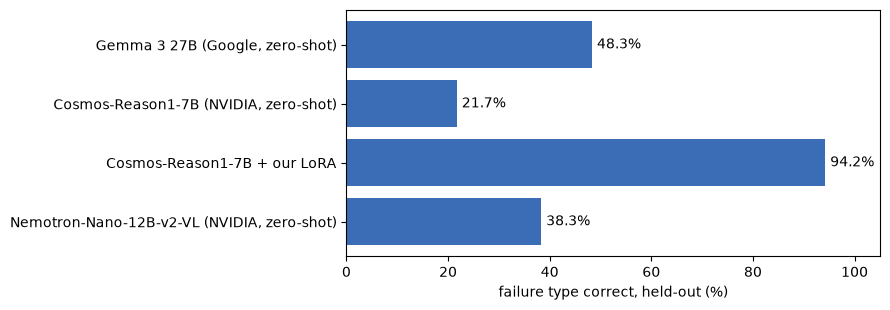

In [10]:
rows = []
for name, run in RUNS.items():
    f = BENCH / run / "summary.json"
    if f.exists():
        s = json.loads(f.read_text())
        rows.append((name, s["overall"]["failure_type_acc"], s["false_alarm_rate_on_clean"],
                     s["miss_rate_on_faults"], s["latency_ms"].get("p50")))
print(f"{'verifier':<45} {'correct':>8} {'false alarms':>13} {'missed':>8} {'p50 ms':>8}")
for r in rows:
    print(f"{r[0]:<45} {r[1]:>7}% {r[2]!s:>12}% {r[3]!s:>7}% {r[4]!s:>8}")

if rows:
    fig, ax = plt.subplots(figsize=(9, 3.2))
    ax.barh([r[0] for r in rows][::-1], [r[1] for r in rows][::-1], color="#3a6db5")
    for i, r in enumerate(rows[::-1]):
        ax.text(r[1] + 1, i, f"{r[1]}%", va="center")
    ax.set_xlim(0, 105); ax.set_xlabel("failure type correct, held-out (%)")
    plt.tight_layout(); plt.show()

In [11]:
# What each policy does with the fine-tuned verifier: how many bad parts reach the fixture.
f = ROOT / "runs" / "decisions" / "feval_v1__cosmos_tuned" / "summary.json"
if f.exists():
    cond = json.loads(f.read_text())["conditions"]
    names = {"A": "no checks", "B": "today's factory (gripper only)", "C": "ours + Nemotron", "D": "ours + lookup table"}
    print(f"{'policy':<34} {'correct':>8} {'bad parts shipped':>18} {'false alarms':>13}")
    for k in "ABCD":
        o = cond[k]["outcomes"]
        print(f"{k} {names[k]:<32} {cond[k]['correct_pct']:>7}% {o.get('quality_escape', 0):>18} {o.get('false_alarm', 0):>13}")

policy                              correct  bad parts shipped  false alarms
A no checks                           16.7%                 60             0
B today's factory (gripper only)      21.7%                 60             0
C ours + Nemotron                     95.8%                  0             5
D ours + lookup table                 95.8%                  0             5


## Step 5 — the fine-tune

Training data = the same prompt the verifier sees + the two photos + the correct answer,
built by `finetune/build_dataset.py`. Training ran on a Nebius H100 (`finetune/train_lora.py`).

In [12]:
f = ROOT / "finetune" / "data" / "train.jsonl"
if f.exists():
    ex = json.loads(f.open().readline())
    print("images:", ex["images"])
    print("\nquestion (first 400 characters):\n", ex["user"][:400], "...")
    print("\nthe answer the model learns to write:\n", ex["target"])

images: ['ftrain_v1/images/10000_overview.png', 'ftrain_v1/images/10000_closeup.png']

question (first 400 characters):
 Checkpoint: CP_PRE_GRASP. The robot is about to grasp the part waiting on the carrier.
The correct part is: an M16 hex nut: bright steel, 24 mm across the flats, a threaded hole, undamaged.
Check, in this order, and report the FIRST problem you find:
1. Shape and size: is it a hex nut about half as wide as the AprilTag's black square?
   A bolt (a threaded shaft standing up), a clearly smaller nut ...

the answer the model learns to write:
 {"checkpoint": "CP_PRE_GRASP", "step_ok": false, "failure_type": "wrong_part", "evidence": "The nut is too small: it leaves a wide gap to the outline on every side.", "location_hint": "carrier", "confidence": 0.9}


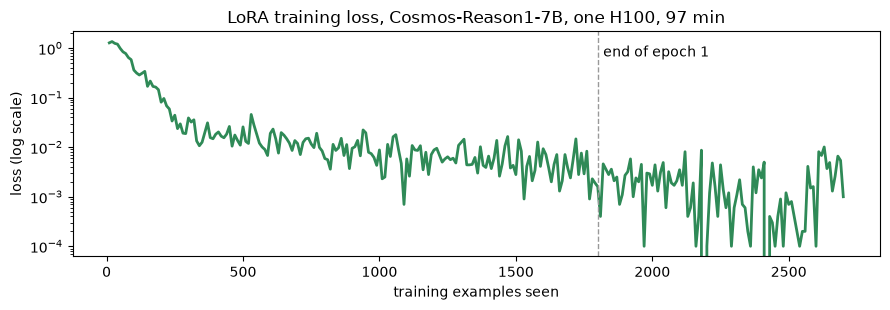

In [13]:
import re
f = ROOT / "finetune" / "data" / "gen" / "train_full.log"
if f.exists():
    pts = [(int(m[1]), float(m[2])) for m in re.finditer(r"\[train\] (\d+)/\d+ loss ([\d.]+)", f.read_text())]
    fig, ax = plt.subplots(figsize=(9, 3.2))
    ax.plot([p[0] for p in pts], [p[1] for p in pts], color="#2f8a57", lw=2)
    ax.set_yscale("log"); ax.set_xlabel("training examples seen"); ax.set_ylabel("loss (log scale)")
    ax.axvline(1800, color="#999", ls="--", lw=1); ax.text(1820, max(p[1] for p in pts) / 2, "end of epoch 1")
    ax.set_title("LoRA training loss, Cosmos-Reason1-7B, one H100, 97 min")
    plt.tight_layout(); plt.show()

7 mistakes out of 120


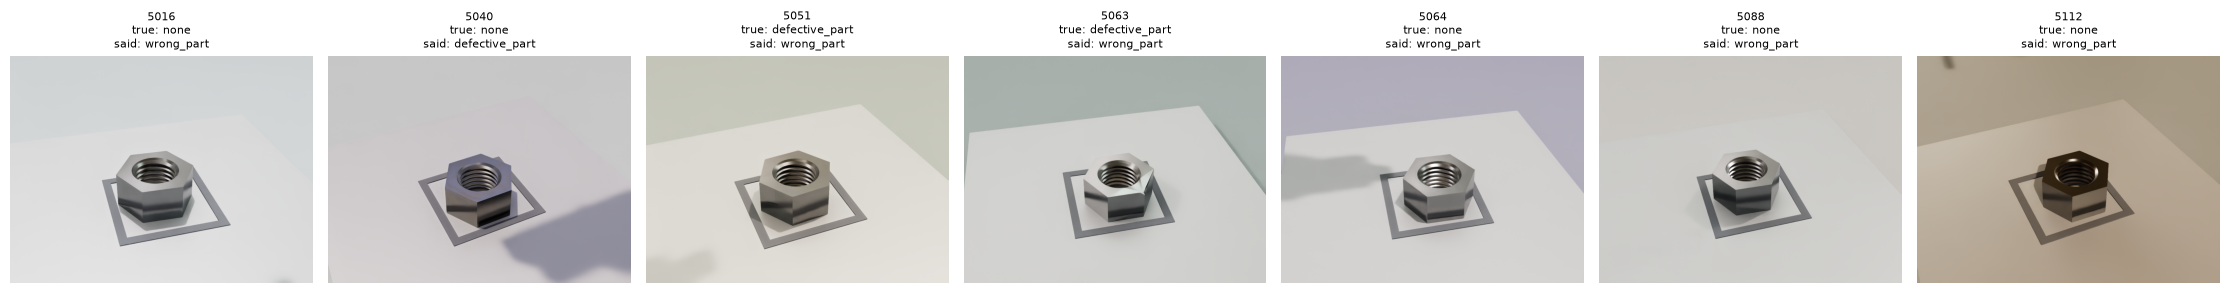

In [14]:
# The fine-tuned model's mistakes on the held-out scenes, with the photo it saw.
tuned = load_rows("feval_v1__cosmos_tuned")
if tuned and HAVE_RUNS:
    wrong = [r for r in tuned.values() if (r["pred"] or {}).get("failure_type") != r["exp"]["failure_type"]]
    print(len(wrong), "mistakes out of", len(tuned))
    fig, axes = plt.subplots(1, len(wrong), figsize=(3.2 * len(wrong), 3.2))
    for ax, r in zip(axes, wrong):
        ax.imshow(Image.open(SCENES / "images" / f"{r['seed']}_closeup.png"))
        ax.set_title(f"{r['seed']}\ntrue: {r['exp']['failure_type']}\nsaid: {r['pred']['failure_type']}", fontsize=8)
        ax.axis("off")
    plt.tight_layout(); plt.show()

## Optional — one live call to the verifier on Nebius (< 1 cent)

Sends seed 5009's photos to the verifier model in `.env` (Gemma 3 27B on Token Factory),
through exactly the code the benchmark uses. Set `RUN_LIVE = True` to run it.

In [15]:
RUN_LIVE = False

if RUN_LIVE and HAVE_RUNS:
    import yaml
    from _common import client_for, load_dotenv, require_env
    from bench_verifier import build_prompt, call_verifier
    load_dotenv()
    cfg = yaml.safe_load((ROOT / "config" / "selfheal_fastener.yaml").read_text())
    client = client_for(cfg["verifier"])
    model = require_env(cfg["verifier"]["model_id_env"])
    prompt = build_prompt(cfg, spec.checkpoint, ["overview", "closeup"])
    res = call_verifier(client, model, cfg, prompt,
                        [SCENES / "images" / f"{SEED}_overview.png", SCENES / "images" / f"{SEED}_closeup.png"])
    print(model, f"{res['latency_ms']:.0f} ms")
    print(res["parsed"] or res["error"])
else:
    print("skipped (RUN_LIVE = False)")

skipped (RUN_LIVE = False)
